# Model Optimization Pipeline — Revised

**Stealth · Task 2210 · revision prepared October 20, 2026**

This notebook revises the [original TF-IDF + LinearSVC project](../../Model%20Optimization%20Pipeline.ipynb) in response to [mentor feedback](../../feedback/task-2210-mentor-feedback.md). The original is preserved. The revision makes search budgets, randomness, timing, and parameter analysis explicit.

| Comparison choice | Fixed before running the benchmark |
| --- | --- |
| Data and classifier | The original four computer-related 20 Newsgroups categories; TF-IDF followed by LinearSVC. |
| Evaluation | The same five stratified training folds for every trial; macro F1 is the selection objective. |
| Search budget | 32 full CV evaluations per strategy per repetition; no early stopping. |
| Resources | One Ray CPU per trial, one concurrent trial, one numerical-library thread. |
| Repetitions | Search seeds 42, 43, 44; CV and model seeds stay 42. Strategy order rotates. |
| Selection | Select configurations and the primary-seed strategy by training CV only. |

Equal trial counts and concurrency do **not** imply equal runtime or identical search spaces. Grid searches four discrete C values; random and Bayesian searches sample a continuous log-uniform C range. Three search seeds describe limited algorithmic variability on fixed folds, not sampling uncertainty or statistical significance. The official test split was already examined in the original project, so the test results below are a descriptive benchmark, **not a newly untouched validation set**.


In [1]:
from pathlib import Path
import os
import contextlib
import hashlib
import importlib.metadata as metadata
import json
import logging
import platform
import tempfile
import time
import warnings

# Set before importing numerical libraries and before starting Ray workers.
THREAD_ENV = {key: '1' for key in [
    'OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS',
    'VECLIB_MAXIMUM_THREADS', 'NUMEXPR_NUM_THREADS',
]}
os.environ.update(THREAD_ENV)
os.environ['RAY_USAGE_STATS_ENABLED'] = '0'
os.environ['RAY_AIR_NEW_OUTPUT'] = '0'

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ray
from ray import tune
from ray.tune.search.basic_variant import BasicVariantGenerator
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='pkg_resources is deprecated as an API.*', category=UserWarning)
    from ray.tune.search.hyperopt import HyperOptSearch
from IPython.display import display, Markdown
from sklearn.datasets import fetch_20newsgroups
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits

warnings.filterwarnings('error', category=ConvergenceWarning)
logging.getLogger('ray.tune').setLevel(logging.ERROR)
logging.getLogger('hyperopt').setLevel(logging.ERROR)
ARTIFACTS = Path('artifacts').resolve()
ARTIFACTS.mkdir(exist_ok=True)
RUN_STORAGE = Path(tempfile.mkdtemp(prefix='st2210-')).resolve()
SEARCH_SEEDS = [42, 43, 44]
MODEL_SEED = CV_SEED = 42
STRATEGIES = ['Grid', 'Random', 'Bayesian']
COLORS = {'Baseline': '#777777', 'Grid': '#507c9d', 'Random': '#a53b4a', 'Bayesian': '#668549'}
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
versions = {'python': platform.python_version(), 'platform': platform.system(),
            'machine': platform.machine(), 'logical_cpu_count': os.cpu_count()}
for package in ['numpy', 'pandas', 'scipy', 'matplotlib', 'scikit-learn',
                'ray', 'hyperopt', 'threadpoolctl', 'nbformat', 'nbclient', 'nbconvert', 'ipykernel']:
    versions[package] = metadata.version(package)
(ARTIFACTS / 'environment.json').write_text(json.dumps(versions, indent=2))
display(pd.Series(versions, name='Executed environment').to_frame())


,Executed environment
python,3.13.9
platform,Darwin
machine,arm64
logical_cpu_count,12
numpy,2.3.5
pandas,2.3.3
scipy,1.16.3
matplotlib,3.10.6
scikit-learn,1.7.2
ray,2.56.0


## 1. Data and shared training folds

Use the same official train/test split and the same header/footer/quote removal as the original. Empty documents after removal are retained in both partitions, as before. No document text or personal contact details from the corpus are exported. A hash-and-label manifest identifies the exact inputs without copying their text.

TF-IDF vocabulary and inverse document frequencies are fitted **inside each training fold**. The test documents do not enter fitting or configuration selection. The fold seed and classifier seed remain fixed across repetitions so the search seed changes the proposals, not the validation problem.


In [2]:
CATEGORIES = ['comp.graphics', 'comp.os.ms-windows.misc',
              'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware']
DATA_HOME = Path(os.environ.get('SCIKIT_LEARN_DATA', Path.home() / 'scikit_learn_data'))
train_data = fetch_20newsgroups(
    subset='train', categories=CATEGORIES, remove=('headers', 'footers', 'quotes'),
    shuffle=True, random_state=42, data_home=DATA_HOME,
)
test_data = fetch_20newsgroups(
    subset='test', categories=CATEGORIES, remove=('headers', 'footers', 'quotes'),
    shuffle=True, random_state=42, data_home=DATA_HOME,
)
x_train, y_train = train_data.data, train_data.target
x_test, y_test = test_data.data, test_data.target
class_names = train_data.target_names
assert class_names == test_data.target_names and len(class_names) == 4
cv_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=CV_SEED).split(x_train, y_train))
fold_assignment = np.full(len(y_train), -1)
for fold, (tr, va) in enumerate(cv_folds, start=1):
    assert set(tr).isdisjoint(va)
    fold_assignment[va] = fold
assert (fold_assignment > 0).all()
manifest_rows = []
for split, documents, targets in [('train', x_train, y_train), ('test', x_test, y_test)]:
    for i, (document, target) in enumerate(zip(documents, targets)):
        manifest_rows.append({'split': split, 'document_index': i, 'label': int(target),
            'document_sha256': hashlib.sha256(document.encode('utf-8')).hexdigest(),
            'empty_after_removal': not document.strip(),
            'validation_fold': int(fold_assignment[i]) if split == 'train' else None})
pd.DataFrame(manifest_rows).to_csv(ARTIFACTS / 'data_manifest.csv', index=False)
distribution = pd.DataFrame({'class': class_names,
    'train_n': np.bincount(y_train), 'test_n': np.bincount(y_test)})
distribution.to_csv(ARTIFACTS / 'class_distribution.csv', index=False)
display(distribution)
print('Empty documents retained:', sum(not s.strip() for s in x_train), 'train;',
      sum(not s.strip() for s in x_test), 'test.')


,class,train_n,test_n
0,comp.graphics,584,389
1,comp.os.ms-windows.misc,591,394
2,comp.sys.ibm.pc.hardware,590,392
3,comp.sys.mac.hardware,578,385


Empty documents retained: 68 train; 40 test.


## 2. Pipeline, search spaces, and baseline

Every trial runs all five shared folds and reports macro F1. The baseline uses C=1, unigrams, min_df=1, max_df=1, ordinary term frequencies, and no class weighting.

LinearSVC's iteration limit is increased from the original 5,000 to 10,000. Convergence warnings raise errors instead of being silently suppressed.

| Parameter | Grid | Random and Bayesian |
| --- | --- | --- |
| C | 0.01, 0.1, 1, 10 | Log-uniform from 0.01 to 10 |
| ngram_range | (1,1), (1,2) | Same two choices |
| min_df | 1, 2 | Same two choices |
| sublinear_tf | False, True | Same two choices |
| max_df / class_weight | 1.0 / None | Fixed identically |

The grid contains 4 × 2 × 2 × 2 = 32 configurations. Random and Bayesian searches each propose 32 configurations; duplicates, if any, still consume the trial budget. HyperOpt uses TPE with five initial random proposals. Its continuous search space matches random search. Search results on these folds are selection scores and can be optimistic after tuning; they are not nested-CV estimates of generalization.


In [3]:
BASELINE_CONFIG = {'C': 1.0, 'ngram_range': [1, 1], 'min_df': 1,
                   'max_df': 1.0, 'sublinear_tf': False, 'class_weight': None}

def build_model(config):
    return Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=tuple(config['ngram_range']),
            min_df=int(config['min_df']), max_df=float(config['max_df']),
            sublinear_tf=bool(config['sublinear_tf']))),
        ('classifier', LinearSVC(C=float(config['C']), class_weight=config['class_weight'],
            max_iter=10000, random_state=MODEL_SEED)),
    ])

def evaluate_configuration(config, documents, targets, folds):
    # Runs in each Ray worker; warnings and thread limits must apply there too.
    with warnings.catch_warnings(), threadpool_limits(limits=1):
        warnings.filterwarnings('error', category=ConvergenceWarning)
        started = time.perf_counter()
        scores = cross_val_score(build_model(config), documents, targets, cv=folds,
                                 scoring='f1_macro', n_jobs=1, error_score='raise')
        duration = time.perf_counter() - started
    result = {'mean_cv_f1': float(scores.mean()), 'std_cv_f1': float(scores.std(ddof=1)),
              'cv_seconds': duration}
    result.update({f'fold_{i + 1}_f1': float(value) for i, value in enumerate(scores)})
    return result

def search_space(strategy):
    if strategy == 'Grid':
        return {'C': tune.grid_search([0.01, 0.1, 1.0, 10.0]),
                'ngram_range': tune.grid_search([[1, 1], [1, 2]]),
                'min_df': tune.grid_search([1, 2]),
                'sublinear_tf': tune.grid_search([False, True]),
                'max_df': 1.0, 'class_weight': None}
    return {'C': tune.loguniform(0.01, 10.0),
            'ngram_range': tune.choice([[1, 1], [1, 2]]),
            'min_df': tune.choice([1, 2]), 'sublinear_tf': tune.choice([False, True]),
            'max_df': 1.0, 'class_weight': None}

baseline_cv = evaluate_configuration(BASELINE_CONFIG, x_train, y_train, cv_folds)
(ARTIFACTS / 'baseline_cv.json').write_text(json.dumps(baseline_cv, indent=2))
display(pd.Series(baseline_cv, name='Baseline training CV').to_frame())


,Baseline training CV
mean_cv_f1,0.762233
std_cv_f1,0.018569
cv_seconds,0.834525
fold_1_f1,0.770634
fold_2_f1,0.756996
fold_3_f1,0.747475
fold_4_f1,0.790349
fold_5_f1,0.745713


## 3. Fair resource limits and actual completion order

The nine searches run sequentially. Each strategy appears first, second, and third once: Grid→Random→Bayesian, Random→Bayesian→Grid, Bayesian→Grid→Random. Ray startup and data loading occur outside search timing. Worker creation, scheduling, search suggestions, result transfer, and logging during `fit()` are included in wall-clock search time.

A callback records **actual trial completion order** and elapsed wall time from that search's start. This avoids treating a results-table row order as execution order. Each completed trial is saved immediately. Search wall time is reported separately from the sum of time spent inside five-fold CV; their difference is operational overhead, not a measurement of pure optimizer computation. Operating-system caching and other system load still affect timing.


In [4]:
def clean_config(config):
    return {'C': float(config['C']), 'ngram_range': [int(v) for v in config['ngram_range']],
            'min_df': int(config['min_df']), 'max_df': float(config['max_df']),
            'sublinear_tf': bool(config['sublinear_tf']), 'class_weight': config['class_weight']}

class CompletionRecorder(tune.Callback):
    def __init__(self, strategy, seed, destination):
        self.strategy, self.seed, self.destination = strategy, seed, str(destination)
        self.rows = []
        self.started = None

    def on_trial_complete(self, iteration, trials, trial, **info):
        result = trial.last_result
        config = clean_config(trial.config)
        row = {'strategy': self.strategy, 'search_seed': self.seed,
               'completed_trial': len(self.rows) + 1, 'trial_id': trial.trial_id,
               'elapsed_wall_seconds': time.perf_counter() - self.started,
               'C': config['C'], 'ngram_range': json.dumps(config['ngram_range']),
               'min_df': config['min_df'], 'max_df': config['max_df'],
               'sublinear_tf': config['sublinear_tf'], 'class_weight': config['class_weight'],
               'config_json': json.dumps(config, sort_keys=True)}
        for metric in ['mean_cv_f1', 'std_cv_f1', 'cv_seconds'] + [f'fold_{i}_f1' for i in range(1, 6)]:
            row[metric] = float(result[metric])
        self.rows.append(row)
        pd.DataFrame(self.rows).to_csv(self.destination, index=False)

if ray.is_initialized():
    raise RuntimeError('Run in a fresh kernel: an existing Ray session could change resource limits.')
with open(RUN_STORAGE / 'driver-startup.log', 'w') as startup_log:
    with contextlib.redirect_stdout(startup_log), contextlib.redirect_stderr(startup_log):
        ray.init(num_cpus=1, include_dashboard=False, log_to_driver=False,
                 logging_level=logging.ERROR, runtime_env={'env_vars': THREAD_ENV})
ray_trainable = tune.with_resources(tune.with_parameters(
    evaluate_configuration, documents=x_train, targets=y_train, folds=cv_folds), {'cpu': 1})

def run_search(strategy, seed, order_position):
    if strategy == 'Bayesian':
        algorithm = HyperOptSearch(metric='mean_cv_f1', mode='max',
                                   random_state_seed=seed, n_initial_points=5)
    else:
        algorithm = BasicVariantGenerator(random_state=seed)
    recorder = CompletionRecorder(strategy, seed, ARTIFACTS / f'trials_{strategy.lower()}_seed{seed}.csv')
    tuner = tune.Tuner(
        ray_trainable, param_space=search_space(strategy),
        tune_config=tune.TuneConfig(metric='mean_cv_f1', mode='max', search_alg=algorithm,
            num_samples=1 if strategy == 'Grid' else 32, max_concurrent_trials=1, reuse_actors=False),
        run_config=tune.RunConfig(name=f'{strategy.lower()}_seed{seed}',
            storage_path=str(RUN_STORAGE / 'ray-results'), verbose=0, log_to_file=True,
            callbacks=[recorder], failure_config=tune.FailureConfig(max_failures=0, fail_fast=True)),
    )
    with open(RUN_STORAGE / f'{strategy.lower()}_seed{seed}_driver.log', 'w') as log:
        with contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
            recorder.started = time.perf_counter()
            result_grid = tuner.fit()
            wall_seconds = time.perf_counter() - recorder.started
    if result_grid.num_errors or len(recorder.rows) != 32:
        raise RuntimeError(f'{strategy} seed {seed}: expected 32 successful trials; '
                           f'got {len(recorder.rows)} completions and {result_grid.num_errors} errors.')
    trial_table = pd.DataFrame(recorder.rows)
    assert trial_table['elapsed_wall_seconds'].is_monotonic_increasing
    assert np.isfinite(trial_table['mean_cv_f1']).all()
    assert np.allclose(trial_table[[f'fold_{i}_f1' for i in range(1, 6)]].mean(axis=1), trial_table.mean_cv_f1)
    trial_table['best_cv_f1_so_far'] = trial_table.mean_cv_f1.cummax()
    trial_table.to_csv(recorder.destination, index=False)
    best = trial_table.sort_values(['mean_cv_f1', 'completed_trial'], ascending=[False, True]).iloc[0]
    summary = {'strategy': strategy, 'search_seed': seed, 'order_position': order_position,
        'successful_trials': len(trial_table), 'unique_configurations': trial_table.config_json.nunique(),
        'search_wall_seconds': wall_seconds, 'total_cv_seconds': trial_table.cv_seconds.sum(),
        'other_seconds': wall_seconds - trial_table.cv_seconds.sum(),
        'best_cv_f1': best.mean_cv_f1, 'best_cv_fold_sd': best.std_cv_f1,
        'best_completed_trial': int(best.completed_trial), 'best_config_json': best.config_json}
    return trial_table, summary

all_trial_parts, search_records = [], []
try:
    for repeat, seed in enumerate(SEARCH_SEEDS):
        order = STRATEGIES[repeat:] + STRATEGIES[:repeat]
        for position, strategy in enumerate(order, start=1):
            table, record = run_search(strategy, seed, position)
            all_trial_parts.append(table)
            search_records.append(record)
            # Persist incrementally so completed work remains inspectable on interruption.
            pd.concat(all_trial_parts, ignore_index=True).to_csv(ARTIFACTS / 'all_trials.csv', index=False)
            pd.DataFrame(search_records).to_csv(ARTIFACTS / 'search_summary.csv', index=False)
            print(f'{strategy} seed {seed}: 32 complete; CV F1={record["best_cv_f1"]:.4f}; '
                  f'wall={record["search_wall_seconds"]:.1f}s', flush=True)
except BaseException:
    ray.shutdown()
    raise
all_trials = pd.concat(all_trial_parts, ignore_index=True)
search_summary = pd.DataFrame(search_records)
assert len(all_trials) == 288 and len(search_summary) == 9
display(search_summary[['strategy', 'search_seed', 'unique_configurations', 'best_cv_f1',
                        'search_wall_seconds', 'total_cv_seconds', 'other_seconds']].round(4))


Random seed 44: 32 complete; CV F1=0.7730; wall=119.4s


,strategy,search_seed,unique_configurations,best_cv_f1,search_wall_seconds,total_cv_seconds,other_seconds
0,Grid,42,32,0.7717,134.3484,57.7066,76.6419
1,Random,42,32,0.7731,129.7405,54.6669,75.0736
2,Bayesian,42,32,0.7739,151.2362,74.7502,76.4860
3,Random,43,32,0.7734,127.2135,53.0783,74.1352
4,Bayesian,43,32,0.7676,115.9129,38.6167,77.2961
5,Grid,43,32,0.7717,134.4935,58.8288,75.6647
6,Bayesian,44,32,0.7757,129.2616,56.5806,72.6810
7,Grid,44,32,0.7717,136.5792,60.0427,76.5365
8,Random,44,32,0.7730,119.4320,46.4292,73.0029


## 4. Search progress and timing across three seeds

Curves begin when the first evaluated configuration completes. Each step shows the best training-CV macro F1 available at that moment. The horizontal baseline is one fixed configuration, not a search. Lines are separate repetitions; they are not confidence bands. Grid exhaustively evaluates the same 32 configurations on the same folds every time, so its best score should be the same; repeated grid runs measure timing variability.


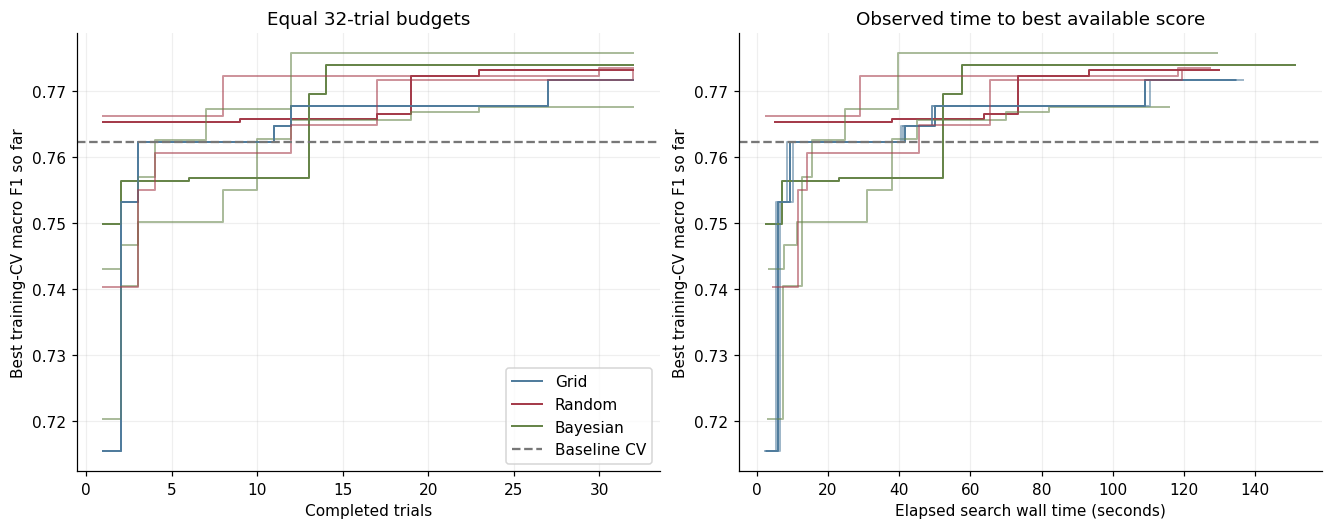

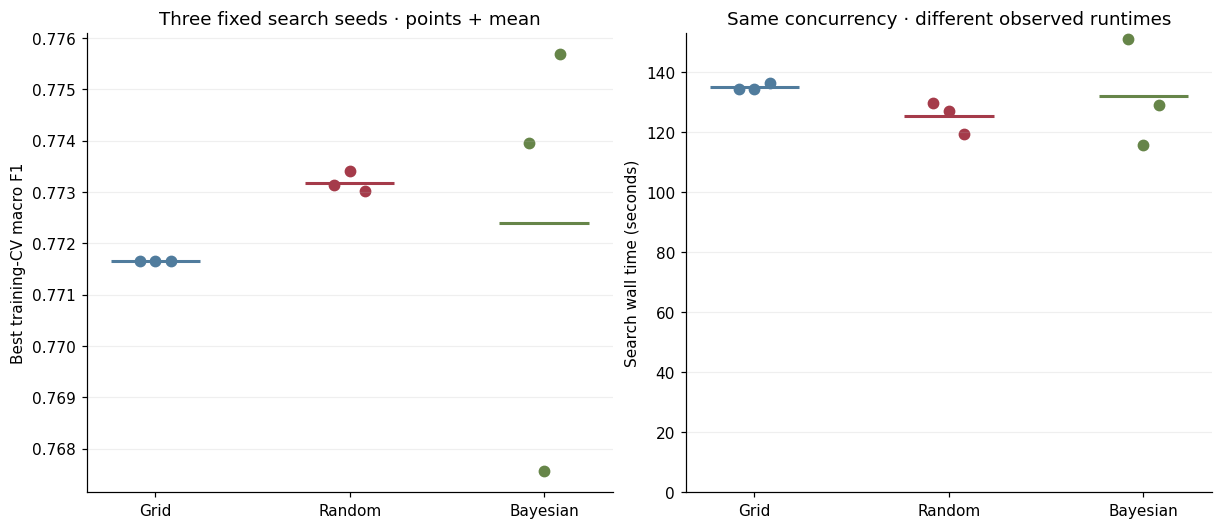

best_cv_f1                         search_wall_seconds           \
               mean     std     min     max                mean      std   
strategy                                                                   
Bayesian     0.7724  0.0043  0.7676  0.7757            132.1369  17.8363   
Grid         0.7717  0.0000  0.7717  0.7717            135.1404   1.2481   
Random       0.7732  0.0002  0.7730  0.7734            125.4620   5.3728   

                             total_cv_seconds                             \
               min       max             mean      std      min      max   
strategy                                                                   
Bayesian  115.9129  151.2362          56.6492  18.0668  38.6167  74.7502   
Grid      134.3484  136.5792          58.8593   1.1683  57.7066  60.0427   
Random    119.4320  129.7405          51.3914   4.3702  46.4292  54.6669   

         other_seconds                            
                  mean     std      min      max  
strategy                                          
Bayesian       75.4877  2.4642  72.6810  77.2961  
Grid           76.2810  0.5364  75.6647  76.6419  
Random         74.0706  1.0369  73.0029  75.0736

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), constrained_layout=True)
for (strategy, seed), table in all_trials.groupby(['strategy', 'search_seed'], sort=False):
    table = table.sort_values('completed_trial')
    for ax, column in zip(axes, ['completed_trial', 'elapsed_wall_seconds']):
        ax.step(table[column], table.best_cv_f1_so_far, where='post', color=COLORS[strategy],
                alpha=0.55 if seed != 42 else 1.0, linewidth=1.3,
                label=strategy if seed == 42 else None)
for ax in axes:
    ax.axhline(baseline_cv['mean_cv_f1'], linestyle='--', color=COLORS['Baseline'], label='Baseline CV')
    ax.set_ylabel('Best training-CV macro F1 so far')
    ax.grid(alpha=0.2)
axes[0].set_xlabel('Completed trials')
axes[1].set_xlabel('Elapsed search wall time (seconds)')
axes[0].legend(loc='lower right')
axes[0].set_title('Equal 32-trial budgets')
axes[1].set_title('Observed time to best available score')
fig.savefig(ARTIFACTS / '01_search_progress.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.7), constrained_layout=True)
for i, strategy in enumerate(STRATEGIES):
    subset = search_summary[search_summary.strategy == strategy].sort_values('search_seed')
    axes[0].scatter(np.full(3, i) + np.array([-0.08, 0, 0.08]), subset.best_cv_f1,
                    color=COLORS[strategy], s=45)
    axes[1].scatter(np.full(3, i) + np.array([-0.08, 0, 0.08]), subset.search_wall_seconds,
                    color=COLORS[strategy], s=45)
    for ax, col in [(axes[0], 'best_cv_f1'), (axes[1], 'search_wall_seconds')]:
        ax.hlines(subset[col].mean(), i-0.23, i+0.23, color=COLORS[strategy], linewidth=2)
for ax in axes:
    ax.set_xticks(range(3), STRATEGIES)
    ax.grid(axis='y', alpha=0.2)
axes[0].set_ylabel('Best training-CV macro F1')
axes[1].set_ylabel('Search wall time (seconds)')
axes[1].set_ylim(bottom=0)
axes[0].set_title('Three fixed search seeds · points + mean')
axes[1].set_title('Same concurrency · different observed runtimes')
fig.savefig(ARTIFACTS / '02_seed_variation_and_runtime.png', bbox_inches='tight')
plt.show()
repeat_summary = search_summary.groupby('strategy')[['best_cv_f1', 'search_wall_seconds',
                                                     'total_cv_seconds', 'other_seconds']].agg(['mean', 'std', 'min', 'max'])
repeat_summary.to_csv(ARTIFACTS / 'repeat_summary.csv')
display(repeat_summary.round(4))


## 5. CV-selected configurations on the existing test benchmark

Within each strategy and seed, select the highest mean training-CV score; ties use the first completed configuration. Before looking at any test predictions, select the **primary-seed (42) strategy by CV**. All nine selected configurations are then fitted on all training documents and evaluated on the same official test split. The baseline is fitted once. These test scores describe this benchmark; neither the strategy nor the seed is chosen by test performance.

Because the original notebook already exposed the test results, this revision does not claim a new unbiased holdout. Likewise, selecting from 32 configurations can overfit the fixed CV folds. A new dataset or a separately designed nested evaluation would be needed for stronger generalization claims.


Primary seed 42 strategy selected by training CV: Bayesian


,strategy,search_seed,mean_cv_f1,cv_fold_sd,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,final_fit_seconds
0,Baseline,42,0.7622,0.0186,0.7365,0.7365,0.7367,0.7364,0.3287
1,Grid,42,0.7717,0.0213,0.7397,0.7396,0.7399,0.7395,0.8652
2,Random,42,0.7731,0.0209,0.7423,0.7424,0.7425,0.7423,0.9892
3,Bayesian,42,0.7739,0.0197,0.7429,0.7429,0.7431,0.7428,0.9642
4,Random,43,0.7734,0.0185,0.7404,0.7405,0.7406,0.7404,1.2817
5,Bayesian,43,0.7676,0.0154,0.7410,0.7440,0.7414,0.7401,0.2227
6,Grid,43,0.7717,0.0213,0.7397,0.7396,0.7399,0.7395,0.8508
7,Bayesian,44,0.7757,0.0133,0.7526,0.7540,0.7528,0.7518,0.1691
8,Grid,44,0.7717,0.0213,0.7397,0.7396,0.7399,0.7395,0.7137
9,Random,44,0.7730,0.0202,0.7423,0.7422,0.7424,0.7422,0.7139


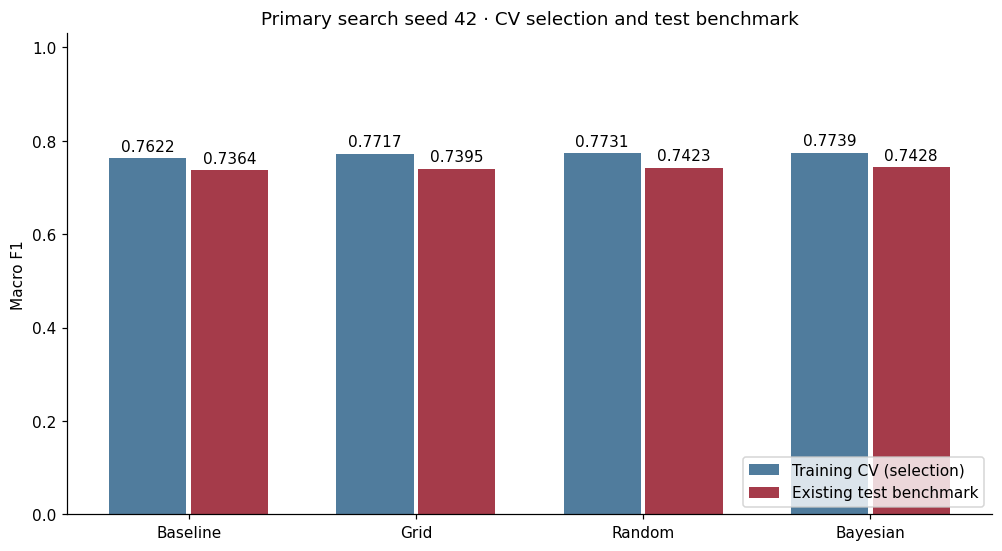

In [6]:
primary_selection = search_summary[search_summary.search_seed == 42].sort_values(
    ['best_cv_f1', 'order_position'], ascending=[False, True]).iloc[0]
selected_primary_strategy = primary_selection.strategy
print('Primary seed 42 strategy selected by training CV:', selected_primary_strategy)

def benchmark_model(name, config, seed, cv_mean, cv_sd):
    estimator = build_model(config)
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.filterwarnings('error', category=ConvergenceWarning)
        started = time.perf_counter()
        estimator.fit(x_train, y_train)
        fit_seconds = time.perf_counter() - started
        prediction = estimator.predict(x_test)
    metrics = {'strategy': name, 'search_seed': seed, 'mean_cv_f1': cv_mean, 'cv_fold_sd': cv_sd,
        'test_accuracy': accuracy_score(y_test, prediction),
        'test_macro_precision': precision_score(y_test, prediction, average='macro', zero_division=0),
        'test_macro_recall': recall_score(y_test, prediction, average='macro', zero_division=0),
        'test_macro_f1': f1_score(y_test, prediction, average='macro', zero_division=0),
        'final_fit_seconds': fit_seconds}
    return metrics, prediction

benchmark_rows, primary_predictions = [], {}
result, baseline_predictions = benchmark_model('Baseline', BASELINE_CONFIG, 42,
    baseline_cv['mean_cv_f1'], baseline_cv['std_cv_f1'])
benchmark_rows.append(result)
primary_predictions['Baseline'] = baseline_predictions
prediction_rows = [{'strategy': 'Baseline', 'search_seed': 42, 'document_index': i,
                    'actual': int(y_test[i]), 'predicted': int(p)} for i, p in enumerate(baseline_predictions)]
for record in search_records:
    result, prediction = benchmark_model(record['strategy'], json.loads(record['best_config_json']),
        record['search_seed'], record['best_cv_f1'], record['best_cv_fold_sd'])
    benchmark_rows.append(result)
    prediction_rows.extend({'strategy': record['strategy'], 'search_seed': record['search_seed'],
        'document_index': i, 'actual': int(y_test[i]), 'predicted': int(p)} for i, p in enumerate(prediction))
    if record['search_seed'] == 42:
        primary_predictions[record['strategy']] = prediction
    pd.DataFrame(benchmark_rows).to_csv(ARTIFACTS / 'benchmark_metrics.csv', index=False)
    pd.DataFrame(prediction_rows).to_csv(ARTIFACTS / 'test_predictions.csv', index=False)
benchmark = pd.DataFrame(benchmark_rows)
display(benchmark.round(4))
for name, prediction in primary_predictions.items():
    report = pd.DataFrame(classification_report(y_test, prediction, labels=range(4),
        target_names=class_names, output_dict=True, zero_division=0)).T
    report.to_csv(ARTIFACTS / f'primary_{name.lower()}_classification_report.csv')

primary_benchmark = benchmark[benchmark.search_seed == 42].set_index('strategy').loc[['Baseline'] + STRATEGIES]
fig, ax = plt.subplots(figsize=(9, 4.9), constrained_layout=True)
positions = np.arange(4)
for offset, column, label, color in [(-0.18, 'mean_cv_f1', 'Training CV (selection)', '#507c9d'),
                                    (0.18, 'test_macro_f1', 'Existing test benchmark', '#a53b4a')]:
    values = primary_benchmark[column].to_numpy()
    bars = ax.bar(positions+offset, values, width=0.34, label=label, color=color)
    ax.bar_label(bars, labels=[f'{v:.4f}' for v in values], padding=3)
ax.set_xticks(positions, primary_benchmark.index)
ax.set_ylim(0, 1.03)
ax.set_ylabel('Macro F1')
ax.set_title('Primary search seed 42 · CV selection and test benchmark')
ax.legend(loc='lower right')
fig.savefig(ARTIFACTS / '03_cv_and_test_comparison.png', bbox_inches='tight')
plt.show()


## 6. Class-specific errors for the primary search seed

The four panels show counts on the same test documents for the baseline and each strategy's CV-selected seed-42 model. Rows are actual classes and columns are predictions. All four are shown, rather than displaying only the model with the highest test score.


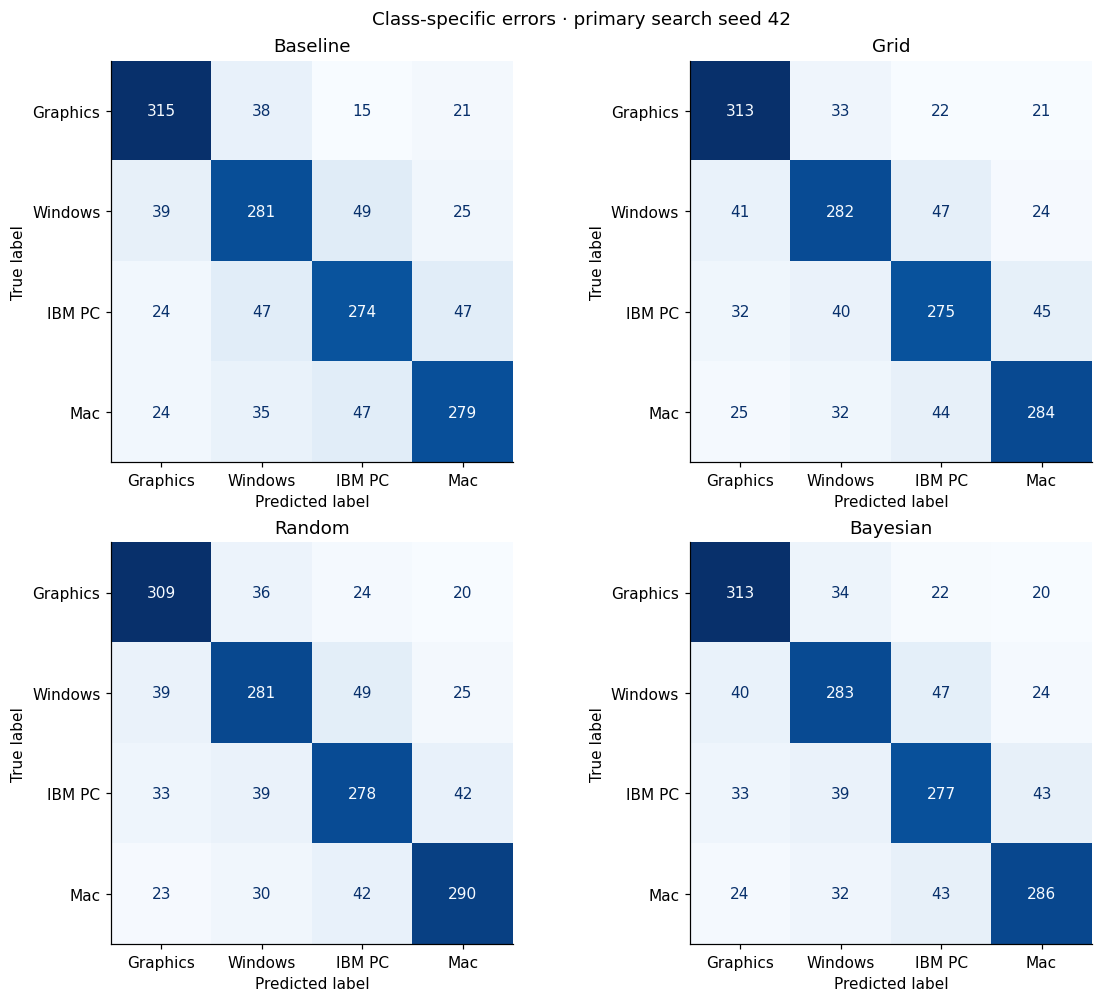

In [7]:
short_names = ['Graphics', 'Windows', 'IBM PC', 'Mac']
assert class_names == ['comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware']
fig, axes = plt.subplots(2, 2, figsize=(10.5, 9), constrained_layout=True)
for ax, name in zip(axes.flat, ['Baseline'] + STRATEGIES):
    ConfusionMatrixDisplay.from_predictions(y_test, primary_predictions[name], labels=range(4),
        display_labels=short_names, cmap='Blues', colorbar=False, ax=ax, values_format='d')
    ax.set_title(name)
fig.suptitle('Class-specific errors · primary search seed 42')
fig.savefig(ARTIFACTS / '04_primary_confusion_matrices.png', bbox_inches='tight')
plt.show()


## 7. Controlled parameter comparisons on the complete grid

Use only the **32 unique seed-42 grid configurations** for parameter analysis. Pooling random and adaptively selected Bayesian trials would mix unequal sampling with parameter effects. Here, paired contrasts change one parameter while holding all other grid parameters fixed. The bars show average differences; whiskers show the minimum and maximum difference across matched settings, **not confidence intervals**. Adjacent C comparisons are included separately.

The C × n-gram heatmap averages over the same four min_df/sublinear_tf combinations in every cell. Changes in the n-gram difference across C illustrate interaction within this finite grid. These are local model-performance comparisons on fixed folds, not causal effects, global feature importance, or significance tests.


,mean,min,max,count
contrast,,,,
Unigrams → unigrams + bigrams,0.0030,-0.0092,0.0191,16
min_df: 1 → 2,-0.0073,-0.0154,0.0004,16
Sublinear TF: off → on,0.0066,0.0009,0.0165,16
C: 0.01 → 0.1,0.0272,0.0170,0.0378,8
C: 0.1 → 1,0.0112,0.0038,0.0204,8
C: 1 → 10,-0.0087,-0.0222,0.0030,8


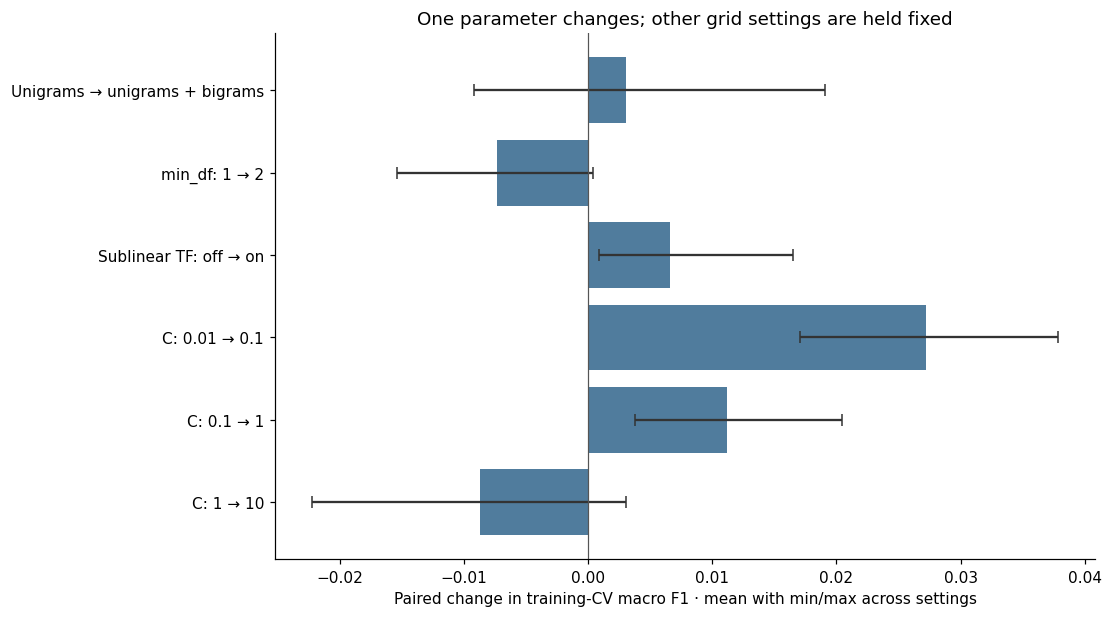

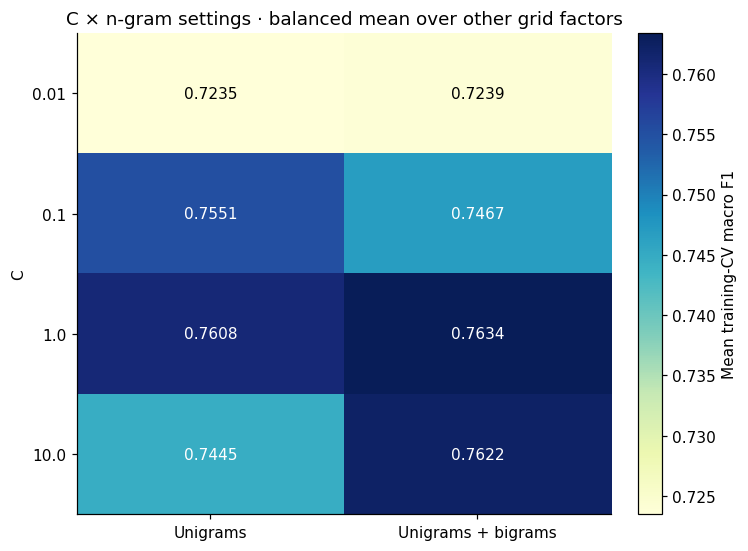

In [8]:
grid = all_trials[(all_trials.strategy == 'Grid') & (all_trials.search_seed == 42)].copy()
grid['ngram_max'] = grid.ngram_range.map(lambda s: json.loads(s)[1])
factors = ['C', 'ngram_max', 'min_df', 'sublinear_tf']
assert len(grid) == 32 and not grid.duplicated(factors).any()
contrast_rows = []
specifications = [('ngram_max', 1, 2, 'Unigrams → unigrams + bigrams'),
                  ('min_df', 1, 2, 'min_df: 1 → 2'),
                  ('sublinear_tf', False, True, 'Sublinear TF: off → on'),
                  ('C', 0.01, 0.1, 'C: 0.01 → 0.1'),
                  ('C', 0.1, 1.0, 'C: 0.1 → 1'),
                  ('C', 1.0, 10.0, 'C: 1 → 10')]
for factor, low, high, label in specifications:
    other_factors = [f for f in factors if f != factor]
    for setting, subset in grid.groupby(other_factors, dropna=False):
        low_row, high_row = subset[subset[factor] == low], subset[subset[factor] == high]
        assert len(low_row) == len(high_row) == 1
        contrast_rows.append({'contrast': label, 'parameter': factor,
            'low_value': str(low), 'high_value': str(high),
            'held_fixed': json.dumps({key: str(value) for key, value in zip(other_factors, setting)}),
            'low_cv_f1': float(low_row.mean_cv_f1.iloc[0]),
            'high_cv_f1': float(high_row.mean_cv_f1.iloc[0]),
            'difference': float(high_row.mean_cv_f1.iloc[0] - low_row.mean_cv_f1.iloc[0])})
contrasts = pd.DataFrame(contrast_rows)
contrasts.to_csv(ARTIFACTS / 'grid_paired_contrasts.csv', index=False)
contrast_summary = contrasts.groupby('contrast', sort=False).difference.agg(['mean', 'min', 'max', 'count'])
contrast_summary.to_csv(ARTIFACTS / 'grid_contrast_summary.csv')
display(contrast_summary.round(4))
fig, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
v = contrast_summary['mean']
ax.barh(contrast_summary.index, v, color='#507c9d')
ax.errorbar(v, np.arange(len(v)),
    xerr=np.vstack([v-contrast_summary['min'], contrast_summary['max']-v]),
    fmt='none', color='#333333', capsize=4)
ax.axvline(0, color='#555555', linewidth=0.8)
ax.invert_yaxis()
ax.set_xlabel('Paired change in training-CV macro F1 · mean with min/max across settings')
ax.set_title('One parameter changes; other grid settings are held fixed')
fig.savefig(ARTIFACTS / '05_grid_paired_contrasts.png', bbox_inches='tight')
plt.show()

interaction = grid.pivot_table(index='C', columns='ngram_max', values='mean_cv_f1', aggfunc='mean').sort_index()
interaction.to_csv(ARTIFACTS / 'grid_C_ngram_interaction.csv')
fig, ax = plt.subplots(figsize=(6.7, 4.9), constrained_layout=True)
im = ax.imshow(interaction.to_numpy(), cmap='YlGnBu', aspect='auto')
ax.set_xticks([0, 1], ['Unigrams', 'Unigrams + bigrams'])
ax.set_yticks(range(len(interaction)), [str(c) for c in interaction.index])
ax.set_ylabel('C')
ax.set_title('C × n-gram settings · balanced mean over other grid factors')
for row in range(len(interaction)):
    for col in range(2):
        val = float(interaction.iloc[row, col])
        ax.text(col, row, f'{val:.4f}', ha='center', va='center',
                color='white' if val > (interaction.to_numpy().min()+interaction.to_numpy().max())/2 else 'black')
fig.colorbar(im, ax=ax, label='Mean training-CV macro F1')
fig.savefig(ARTIFACTS / '06_grid_interaction_heatmap.png', bbox_inches='tight')
plt.show()


## 8. Observed conclusions and limits

The generated summary reports the outcomes, including any disagreements between CV selection, test ranking, and timing. There is no pre-written winning strategy. Interpret the benchmark within its scope:

- Fixed-fold CV is reused for search and therefore subject to selection optimism. Three proposal seeds do not measure dataset/split uncertainty.
- Grid's discrete C values differ from the continuous domain for random/TPE; a comparison cannot isolate search algorithm alone.
- Timing includes operational overhead and machine load, and does not establish a universal fastest method. This single rotation across three runs cannot separate seed, execution order, caching, and system-load effects.
- The test benchmark was inspected previously. No configurations, search seeds, or thresholds are selected based on the revised test results.
- All grid effects depend on these categories, parameter ranges, and fixed folds; they are not global importance or causal statements.

### References

- [Ray 2.56 BasicVariantGenerator: seeded sampling](https://docs.ray.io/en/releases-2.56.0/tune/api/doc/ray.tune.search.basic_variant.BasicVariantGenerator.html)
- [Ray 2.56 HyperOptSearch: TPE and initial random proposals](https://docs.ray.io/en/releases-2.56.0/tune/api/doc/ray.tune.search.hyperopt.HyperOptSearch.html)
- [Ray 2.56 TuneConfig: trial budgets and concurrency](https://docs.ray.io/en/releases-2.56.0/tune/api/doc/ray.tune.TuneConfig.html)
- [Ray 2.56 RunConfig: storage and logging](https://docs.ray.io/en/releases-2.56.0/tune/api/doc/ray.tune.RunConfig.html)
- [scikit-learn: preventing data leakage with Pipeline](https://scikit-learn.org/1.7/common_pitfalls.html)
- [scikit-learn: 20 Newsgroups dataset](https://scikit-learn.org/1.7/datasets/real_world.html#the-20-newsgroups-text-dataset)


In [9]:
selected_row = primary_benchmark.loc[selected_primary_strategy]
baseline_row = primary_benchmark.loc['Baseline']
cv_repeat_means = search_summary.groupby('strategy').best_cv_f1.mean()
wall_means = search_summary.groupby('strategy').search_wall_seconds.mean()
comparison_lines = []
for strategy in STRATEGIES:
    rows = search_summary[search_summary.strategy == strategy]
    test_rows = benchmark[benchmark.strategy == strategy]
    comparison_lines.append(
        f"| {strategy} | {rows.best_cv_f1.mean():.4f} ± {rows.best_cv_f1.std(ddof=1):.4f} | "
        f"{rows.search_wall_seconds.mean():.1f} ± {rows.search_wall_seconds.std(ddof=1):.1f} | "
        f"{test_rows.test_macro_f1.min():.4f}–{test_rows.test_macro_f1.max():.4f} |")
summary = f"""### Task 2210 — observed benchmark results

All 288 trials completed: 32 configurations × 3 strategies × 3 search seeds. Every trial used the same five training folds, one Ray CPU, one concurrent trial, and a one-thread numerical-library limit.

- Baseline training-CV macro F1: **{baseline_cv['mean_cv_f1']:.4f}**; existing-test macro F1: **{baseline_row.test_macro_f1:.4f}**.
- Primary seed 42 strategy selected by training CV: **{selected_primary_strategy}**, CV macro F1 **{selected_row.mean_cv_f1:.4f}**; existing-test macro F1 **{selected_row.test_macro_f1:.4f}**.
- Its observed test difference from baseline is **{selected_row.test_macro_f1-baseline_row.test_macro_f1:+.4f} macro F1**. This is a descriptive comparison on the previously inspected test benchmark.

| Strategy | Best CV F1, mean ± SD across 3 search seeds | Search wall seconds, mean ± SD | Existing-test F1 range |
| --- | --- | --- | --- |
{chr(10).join(comparison_lines)}

SD describes three proposal-seed runs; it is not a confidence interval. Grid scores are repeated deterministic evaluations of one exhaustive grid. No strategy or seed was selected by its test score. Equal trial/concurrency budgets do not mean equal runtime or identical C spaces. Fixed-fold selection optimism, previously seen test data, and machine-dependent timing prevent a general claim that one strategy is best.
"""
display(Markdown(summary))
(ARTIFACTS / 'results_summary.md').write_text(summary)
record = {'revision_date': '2026-10-20', 'search_seeds': SEARCH_SEEDS,
    'cv_seed': CV_SEED, 'model_seed': MODEL_SEED, 'folds': 5, 'trials_per_search': 32,
    'completed_trials': int(len(all_trials)), 'cpu_per_trial': 1, 'max_concurrent_trials': 1,
    'thread_limit': 1, 'primary_seed_cv_selected_strategy': selected_primary_strategy,
    'test_status': 'Previously inspected in original notebook; descriptive benchmark only',
    'search_order': [STRATEGIES[i:]+STRATEGIES[:i] for i in range(3)],
    'data_categories': CATEGORIES, 'train_n': len(y_train), 'test_n': len(y_test),
    'empty_train_n': sum(not s.strip() for s in x_train), 'empty_test_n': sum(not s.strip() for s in x_test),
    'search_records': search_records, 'benchmark_metrics': benchmark_rows}
(ARTIFACTS / 'run_summary.json').write_text(json.dumps(record, indent=2))
ray.shutdown()
print('Completed: clean tables, predictions, figures, and summary saved in artifacts/.')


### Task 2210 — observed benchmark results

All 288 trials completed: 32 configurations × 3 strategies × 3 search seeds. Every trial used the same five training folds, one Ray CPU, one concurrent trial, and a one-thread numerical-library limit.

- Baseline training-CV macro F1: **0.7622**; existing-test macro F1: **0.7364**.
- Primary seed 42 strategy selected by training CV: **Bayesian**, CV macro F1 **0.7739**; existing-test macro F1 **0.7428**.
- Its observed test difference from baseline is **+0.0064 macro F1**. This is a descriptive comparison on the previously inspected test benchmark.

| Strategy | Best CV F1, mean ± SD across 3 search seeds | Search wall seconds, mean ± SD | Existing-test F1 range |
| --- | --- | --- | --- |
| Grid | 0.7717 ± 0.0000 | 135.1 ± 1.2 | 0.7395–0.7395 |
| Random | 0.7732 ± 0.0002 | 125.5 ± 5.4 | 0.7404–0.7423 |
| Bayesian | 0.7724 ± 0.0043 | 132.1 ± 17.8 | 0.7401–0.7518 |

SD describes three proposal-seed runs; it is not a confidence interval. Grid scores are repeated deterministic evaluations of one exhaustive grid. No strategy or seed was selected by its test score. Equal trial/concurrency budgets do not mean equal runtime or identical C spaces. Fixed-fold selection optimism, previously seen test data, and machine-dependent timing prevent a general claim that one strategy is best.


Completed: clean tables, predictions, figures, and summary saved in artifacts/.
